# Project 4: First Machine Learning Classifier

## 1. Project Objective

The objective of this project is to build a Machine Learning
model using the Titanic dataset to predict whether a passenger
survived or not.

## 2. Business Problem

Can we predict passenger survival based on their passenger class,
gender, age, and ticket fare?

## 3. Target Variable

Survived

## 4. Features

- Pclass
- Sex
- Age
- Fare

## 5. Machine Learning Algorithm

Decision Tree Classifier

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = sns.load_dataset("titanic")

df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df = df[["survived", "pclass", "sex", "age", "fare"]]

df.head()

,survived,pclass,sex,age,fare
0,0,3,male,22.0,7.2500
1,1,1,female,38.0,71.2833
2,1,3,female,26.0,7.9250
3,1,1,female,35.0,53.1000
4,0,3,male,35.0,8.0500


In [4]:
df.isnull().sum()

survived      0
pclass        0
sex           0
age         177
fare          0
dtype: int64

In [5]:
df = df.dropna()

print("Missing values removed!")
print("Dataset shape:", df.shape)

Missing values removed!
Dataset shape: (714, 5)


In [6]:
df["sex"] = (df["sex"] == "female").astype(int)

df.head()

,survived,pclass,sex,age,fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 714 entries, 0 to 890
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  714 non-null    int64  
 1   pclass    714 non-null    int64  
 2   sex       714 non-null    int64  
 3   age       714 non-null    float64
 4   fare      714 non-null    float64
dtypes: float64(2), int64(3)
memory usage: 33.5 KB


In [8]:
df.isnull().sum()

survived    0
pclass      0
sex         0
age         0
fare        0
dtype: int64

In [9]:
X = df.drop(columns="survived")
y = df["survived"]

In [10]:
from sklearn.model_selection import train_test_split

In [11]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [12]:
print("Original Dataset:", X.shape)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Original Dataset: (714, 4)
Training Features: (571, 4)
Testing Features: (143, 4)
Training Target: (571,)
Testing Target: (143,)


In [13]:
print("Training Survival Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Survival Distribution:")
print(y_test.value_counts(normalize=True))

Training Survival Distribution:
survived
0    0.593695
1    0.406305
Name: proportion, dtype: float64

Testing Survival Distribution:
survived
0    0.594406
1    0.405594
Name: proportion, dtype: float64


In [14]:
baseline = max(y_test.mean(), 1 - y_test.mean())

print("Baseline Accuracy:", round(baseline, 3))
print("Baseline Accuracy (%):", round(baseline * 100, 2), "%")

Baseline Accuracy: 0.594
Baseline Accuracy (%): 59.44 %


In [15]:
print("Survival Distribution:")
print(y_test.value_counts())

print("\nMost Common Outcome:")
print(y_test.mode()[0])

Survival Distribution:
survived
0    85
1    58
Name: count, dtype: int64

Most Common Outcome:
0


In [16]:
from sklearn.tree import DecisionTreeClassifier

In [17]:
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

In [18]:
model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [19]:
print("Model:", model)
print("Maximum Depth:", model.max_depth)
print("Number of Features:", model.n_features_in_)

Model: DecisionTreeClassifier(max_depth=4, random_state=42)
Maximum Depth: 4
Number of Features: 4


In [20]:
from sklearn.metrics import accuracy_score, confusion_matrix

In [21]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:10])

Predictions:
[1 0 0 0 0 0 0 0 0 1]


In [22]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy, 3))
print("Model Accuracy (%):", round(accuracy * 100, 2), "%")

Model Accuracy: 0.797
Model Accuracy (%): 79.72 %


In [23]:
print("Baseline Accuracy:", round(baseline, 3))
print("Model Accuracy:", round(accuracy, 3))

if accuracy > baseline:
    print("Model performs better than the baseline!")
else:
    print("Model does not beat the baseline.")

Baseline Accuracy: 0.594
Model Accuracy: 0.797
Model performs better than the baseline!


In [24]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[72 13]
 [16 42]]


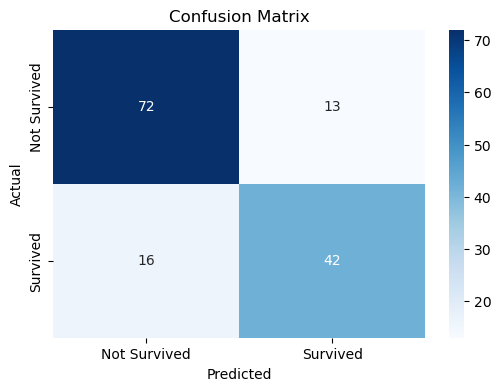

In [25]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [26]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

In [27]:
train_accuracies = []
test_accuracies = []

depths = range(1, 13)

for depth in depths:

    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_pred = tree.predict(X_train)
    test_pred = tree.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

print("Training Accuracies:", train_accuracies)
print("Testing Accuracies:", test_accuracies)

Training Accuracies: [0.7793345008756567, 0.7950963222416813, 0.8178633975481612, 0.8476357267950964, 0.8651488616462347, 0.882661996497373, 0.9159369527145359, 0.9246935201401051, 0.9474605954465849, 0.9562171628721541, 0.9649737302977233, 0.968476357267951]
Testing Accuracies: [0.7832167832167832, 0.7762237762237763, 0.8111888111888111, 0.7972027972027972, 0.7622377622377622, 0.7832167832167832, 0.7832167832167832, 0.7902097902097902, 0.7692307692307693, 0.7622377622377622, 0.7692307692307693, 0.7762237762237763]


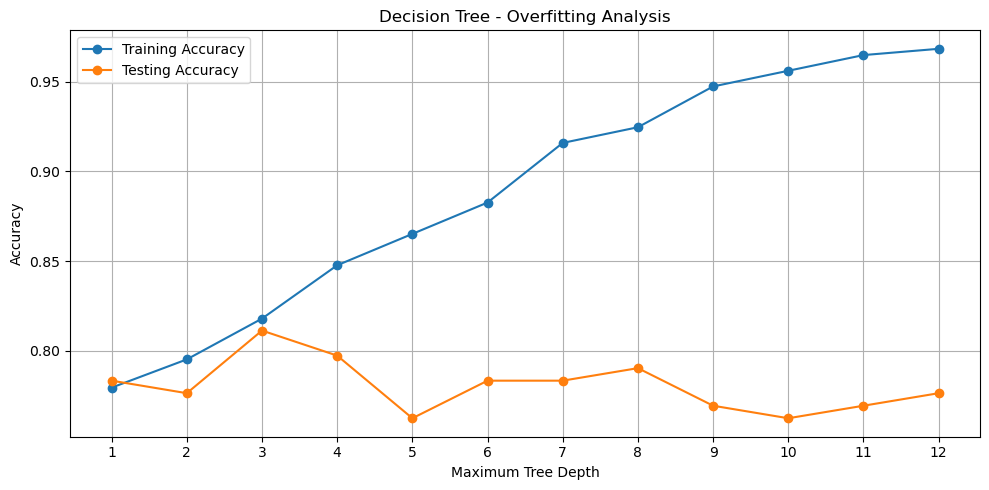

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    depths,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depths,
    test_accuracies,
    marker="o",
    label="Testing Accuracy"
)

plt.title("Decision Tree - Overfitting Analysis")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 7. Overfitting Analysis

I tested the Decision Tree model with maximum depths
ranging from 1 to 12.

I compared training accuracy and testing accuracy
to understand the effect of tree depth.

A very deep decision tree may overfit the training data
and perform poorly on unseen data.

In [29]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

  Feature  Importance
1     sex    0.545075
0  pclass    0.235003
2     age    0.137570
3    fare    0.082352


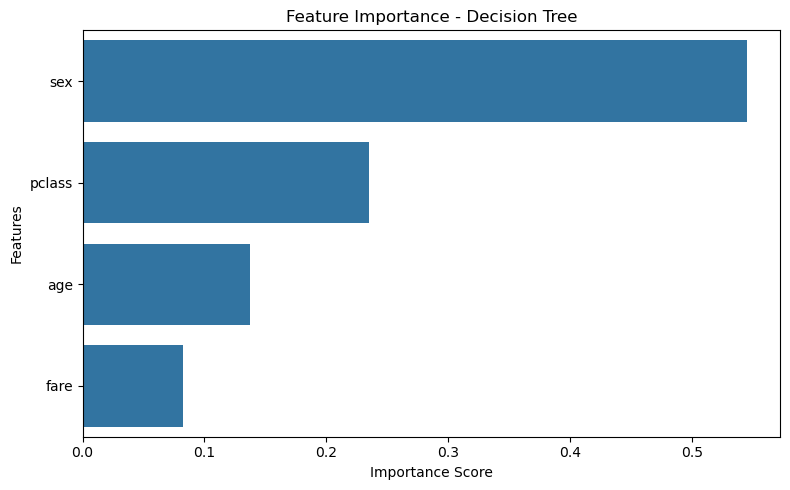

In [30]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Decision Tree")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [31]:
print("========== FINAL MODEL RESULTS ==========")

print("Baseline Accuracy:", round(baseline * 100, 2), "%")

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nFeature Importance:")
print(feature_importance)

print("\nModel Maximum Depth:", model.max_depth)

========== FINAL MODEL RESULTS ==========
Baseline Accuracy: 59.44 %
Model Accuracy: 79.72 %

Feature Importance:
  Feature  Importance
1     sex    0.545075
0  pclass    0.235003
2     age    0.137570
3    fare    0.082352

Model Maximum Depth: 4


# 8. Final Project Summary

## Project Overview
Built a Decision Tree Classification model using the Titanic dataset
to predict passenger survival.

## Model Evaluation
- Baseline Accuracy: [Your result]
- Decision Tree Accuracy: [Your result]
- Algorithm: Decision Tree Classifier
- Maximum Depth: 4

## Important Features
The feature importance analysis identifies which input features
contributed most to the model's predictions.

## Model Limitation
The model uses a limited number of features and a relatively small
dataset after removing missing values. Therefore, predictions may
not represent every passenger accurately.

## What I Learned
1. How to prepare data for Machine Learning.
2. How to split training and testing datasets.
3. How to train a Decision Tree model.
4. How to evaluate model performance.
5. How to identify overfitting.
6. How to understand feature importance.